# Лабораторная работа №5. Градиентный бустинг

Наборы данных, разбиение и метрики - как в ЛР1 (обоснование - в `LR1_knn.ipynb`):
классификация тональности отзывов на аниме (**macro-F1**, accuracy) и регрессия влияния финансовой новости
(**MAE**, RMSE, R2). Итоговое сравнение всех алгоритмов ЛР1-5 - в отдельном ноутбуке `LR_summary.ipynb`.

### Общие функции
Загрузка и разбиение данных, очистка текста, LSA-признаки, метаданные новостей, метрики и сохранение результатов. Эта ячейка одинакова во всех ЛР, чтобы разбиение train/test и метрики совпадали.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent  # ноутбук запускается из labs/
DATA = ROOT / "data"
RESULTS = Path.cwd() / "results"
CACHE = DATA / "cache"
SEED = 42

# Имена признаков (заполняются при построении признаков) - для графиков важности
FEATURE_NAMES = {}
STAT_NAMES = ["log_len", "log_words", "excl_%", "quest_%", "smile_balance_%"]

CLASSES = ["Отрицательный", "Нейтральный", "Положительный"]


def clean_text(s: str) -> str:
    """Нижний регистр, удаление смайлов вида :lonely:, ссылок и лишних пробелов."""
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r":[a-z_]+:", " ", s)
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()


def load_anime():
    """Отзывы на аниме -> (тексты train, тексты test, y train, y test). y: 0/1/2 = отр/нейтр/пол."""
    df = pd.read_csv(DATA / "anime" / "Anime_reviews_RU.csv", index_col=0).dropna(subset=["Text"])
    y = df["Rate"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    X = df["Text"].map(clean_text).to_numpy()
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


def load_finnews():
    """Финансовые новости -> (df train, df test, y train, y test).

    Колонка reasoning исключается: это объяснение оценки, сгенерированное вместе с answer,
    т.е. прямая утечка целевой переменной.
    """
    df = pd.read_csv(DATA / "finnews" / "data.csv", index_col=0)
    df["text"] = df["article_text"].map(clean_text)
    y = df["answer"].to_numpy(dtype=float)
    X = df[["text", "sphere", "source", "date"]].reset_index(drop=True)
    return train_test_split(X, y, test_size=0.2, random_state=SEED)


def text_stats(texts) -> np.ndarray:
    """Простые числовые признаки текста: длина, число слов, доля '!', '?', заглавных скобок-смайлов."""
    rows = []
    for t in texts:
        n = max(len(t), 1)
        rows.append([np.log1p(len(t)), np.log1p(len(t.split())), t.count("!") / n * 100,
                     t.count("?") / n * 100, (t.count(")") - t.count("(")) / n * 100])
    return np.array(rows)


def svd_features(train_texts, test_texts, name, n_components=200):
    """TF-IDF (слова 1-2 граммы) -> TruncatedSVD (LSA) + статистики текста. Кэшируется на диск."""
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / f"{name}_n{len(train_texts)}_svd{n_components}.npz"
    if path.exists():
        d = np.load(path)
        FEATURE_NAMES[name] = list(d["names"])
        return d["tr"], d["te"]
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True)
    a, b = tfidf.fit_transform(train_texts), tfidf.transform(test_texts)
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    tr = np.hstack([svd.fit_transform(a), text_stats(train_texts)])
    te = np.hstack([svd.transform(b), text_stats(test_texts)])
    # Имя LSA-компоненты = 3 слова/биграммы с наибольшим весом в ней (для интерпретации важности)
    vocab = tfidf.get_feature_names_out()
    names = [f"svd{i}: " + "/".join(vocab[np.argsort(-c)[:3]]) for i, c in enumerate(svd.components_)] + STAT_NAMES
    np.savez(path, tr=tr, te=te, names=np.array(names))
    FEATURE_NAMES[name] = names
    return tr, te


def finnews_meta(train_df, test_df):
    """One-hot сферы и источника + день недели публикации."""
    enc = OneHotEncoder(handle_unknown="ignore")
    cols = ["sphere", "source"]
    a = enc.fit_transform(train_df[cols]).toarray()
    b = enc.transform(test_df[cols]).toarray()
    wd = lambda d: pd.get_dummies(pd.to_datetime(d["date"]).dt.weekday).reindex(columns=range(7), fill_value=0).to_numpy(float)
    FEATURE_NAMES["meta"] = list(enc.get_feature_names_out(cols)) + [f"weekday_{i}" for i in range(7)]
    return np.hstack([a, wd(train_df)]), np.hstack([b, wd(test_df)])


def plot_importance(values, names, title, top=20, ax=None):
    """Горизонтальная диаграмма top-N признаков по важности."""
    s = pd.Series(np.asarray(values), index=list(names)).sort_values(ascending=False)[:top][::-1]
    ax = ax or plt.subplots(figsize=(7, 0.3 * top + 1))[1]
    s.plot.barh(ax=ax, title=title, color="#4C72B0")
    return s[::-1]


def stack(*mats):
    """Склейка разреженных/плотных матриц по признакам в CSR."""
    return sparse.hstack([sparse.csr_matrix(m) for m in mats]).tocsr()


def clf_metrics(y_true, y_pred) -> dict:
    """Классификация: macro-F1 (основная, классы несбалансированы) и accuracy."""
    return {"f1_macro": round(float(f1_score(y_true, y_pred, average="macro")), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4)}


def reg_metrics(y_true, y_pred) -> dict:
    """Регрессия: MAE (основная, в пунктах шкалы), RMSE и R2."""
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
            "r2": round(float(r2_score(y_true, y_pred)), 4)}


def save_results(lab: str, results: dict):
    """Сохраняет метрики лабораторной в labs/results/<lab>.json для итогового ноутбука."""
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / f"{lab}.json").write_text(json.dumps(results, ensure_ascii=False, indent=2))


def results_table(results: dict) -> pd.DataFrame:
    """Словарь {задача: {этап: метрики}} -> таблица."""
    return pd.DataFrame([{"задача": t, "этап": s, **m} for t, d in results.items() for s, m in d.items()])

In [2]:
# Структура для метрик: задача -> этап -> {метрика: значение}
res = {"classification": {}, "regression": {}}

In [3]:
# Бустинг sklearn: классический GradientBoosting* (бейзлайн) и гистограммный HistGradientBoosting* (улучшение)
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)

In [4]:
# Загружаем оба набора с фиксированным разбиением train/test (80/20, seed=42) - одинаковым во всех ЛР
Xa_tr, Xa_te, ya_tr, ya_te = load_anime()       # отзывы: тексты и классы 0/1/2
Xf_tr, Xf_te, yf_tr, yf_te = load_finnews()     # новости: таблица (text, sphere, source, date) и оценка влияния
print("anime:", len(Xa_tr), len(Xa_te), " finnews:", len(Xf_tr), len(Xf_te))

anime: 58572 14643  finnews: 8268 2067


In [5]:
# Фолды кросс-валидации (только на train): стратифицированные для классификации
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
kf = KFold(3, shuffle=True, random_state=SEED)

## 2. Бейзлайн

TF-IDF (1000 слов), как у деревьев в ЛР3-4, и `GradientBoostingClassifier()` / `GradientBoostingRegressor()`
по умолчанию: 100 итераций, `learning_rate=0.1`, деревья глубины 3, квадратичная функция потерь для регрессии и
log-loss (softmax) для классификации.

In [6]:
# Бейзлайн-признаки для деревьев: TF-IDF по 1000 самых частых слов (деревья плохо работают с огромным
# разреженным словарём). Для собственных реализаций матрица переводится в плотную float32
vec_a = TfidfVectorizer(max_features=1000)
A_tr, A_te = vec_a.fit_transform(Xa_tr), vec_a.transform(Xa_te)
vec_f = TfidfVectorizer(max_features=1000)
F_tr, F_te = vec_f.fit_transform(Xf_tr["text"]), vec_f.transform(Xf_te["text"])
Ad_tr, Ad_te = A_tr.toarray().astype(np.float32), A_te.toarray().astype(np.float32)
Fd_tr, Fd_te = F_tr.toarray().astype(np.float32), F_te.toarray().astype(np.float32)

In [7]:
# Обучение бустинга по умолчанию и оценка на тесте
gb_c = GradientBoostingClassifier(random_state=SEED).fit(A_tr, ya_tr)
res["classification"]["baseline"] = clf_metrics(ya_te, gb_c.predict(A_te))
gb_r = GradientBoostingRegressor(random_state=SEED).fit(F_tr, yf_tr)
res["regression"]["baseline"] = reg_metrics(yf_te, gb_r.predict(F_te))
res

{'classification': {'baseline': {'f1_macro': 0.4755, 'accuracy': 0.5067}},
 'regression': {'baseline': {'mae': 31.336, 'rmse': 40.048, 'r2': 0.1184}}}

## 3. Улучшение бейзлайна

### 3.1 Гипотезы
1. **H1 - плотные признаки** (LSA + статистики текста, + метаданные для новостей) - как в ЛР3-4.
2. **H2 - больше итераций с ранней остановкой.** 100 итераций с шагом 0.1 мало; больше итераций с меньшим шагом
   и остановкой по валидации дают лучший компромисс смещение/дисперсия. Для скорости используем гистограммную
   реализацию `HistGradientBoosting*` (тот же алгоритм, пороги по бинам).
3. **H3 - сложность деревьев и регуляризация:** число листьев (`max_leaf_nodes`) и L2-регуляризация значений
   листьев (`l2_regularization`).
4. **H4 (регрессия) - функция потерь `absolute_error`**, напрямую оптимизирующая MAE и устойчивая к "хвостам"
   целевой переменной.

In [8]:
# Признаки улучшенного бейзлайна: LSA (TF-IDF 1-2 граммы -> SVD-200) + 5 статистик текста;
# для новостей дополнительно метаданные (сфера, источник, день недели)
Sa_tr, Sa_te = svd_features(Xa_tr, Xa_te, "anime")
Sf_tr, Sf_te = svd_features(Xf_tr["text"], Xf_te["text"], "finnews")
Mf_tr, Mf_te = finnews_meta(Xf_tr, Xf_te)
SMf_tr, SMf_te = np.hstack([Sf_tr, Mf_tr]), np.hstack([Sf_te, Mf_te])
print(Sa_tr.shape, SMf_tr.shape)

(58572, 205) (8268, 218)


In [9]:
# H1: тот же бустинг по умолчанию (100 итераций, глубина 3) на плотных признаках, CV
rows = [{"task": "clf (F1)", "rep": "LSA+stats",
         "cv": cross_val_score(GradientBoostingClassifier(random_state=SEED), Sa_tr, ya_tr, cv=skf, scoring="f1_macro", n_jobs=-1).mean()}]
for name, X in [("LSA+stats", Sf_tr), ("LSA+stats+meta", SMf_tr)]:
    rows.append({"task": "reg (MAE)", "rep": name,
                 "cv": -cross_val_score(GradientBoostingRegressor(random_state=SEED), X, yf_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1).mean()})
pd.DataFrame(rows).round(4)

,task,rep,cv
0,clf (F1),LSA+stats,0.5358
1,reg (MAE),LSA+stats,32.0001
2,reg (MAE),LSA+stats+meta,31.9696


In [10]:
# H2 + H3 (+ H4 для регрессии): сетка для HistGradientBoosting с ранней остановкой (до 1000 итераций)
hgb_common = dict(max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30, random_state=SEED)
rows = []
for lr in [0.05, 0.1]:
    for leaves in [15, 31, 63]:
        for l2 in [0.0, 1.0]:
            f1 = cross_val_score(HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2, **hgb_common),
                                 Sa_tr, ya_tr, cv=skf, scoring="f1_macro").mean()
            maes = {loss: -cross_val_score(HistGradientBoostingRegressor(loss=loss, learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2, **hgb_common),
                                            SMf_tr, yf_tr, cv=kf, scoring="neg_mean_absolute_error").mean()
                    for loss in ["squared_error", "absolute_error"]}
            rows.append({"learning_rate": lr, "max_leaf_nodes": leaves, "l2": l2, "cv_f1": f1,
                         "cv_mae_squared": maes["squared_error"], "cv_mae_absolute": maes["absolute_error"]})
grid = pd.DataFrame(rows)
grid.round(4)

,learning_rate,max_leaf_nodes,l2,cv_f1,cv_mae_squared,cv_mae_absolute
0,0.05,15,0.0,0.5542,31.3164,31.3159
1,0.05,15,1.0,0.5555,31.3329,31.3968
2,0.05,31,0.0,0.5533,31.2803,30.8683
3,0.05,31,1.0,0.5538,31.2234,31.3289
4,0.05,63,0.0,0.5520,31.2452,30.5463
5,0.05,63,1.0,0.5537,31.1729,30.8219
6,0.10,15,0.0,0.5528,31.5826,31.6449
7,0.10,15,1.0,0.5517,31.5332,31.5539
8,0.10,31,0.0,0.5481,31.4709,31.2686
9,0.10,31,1.0,0.5501,31.5229,31.5642


### 3.3-3.5 Улучшенный бейзлайн

In [11]:
# Лучшие конфигурации по CV; для регрессии выбирается и функция потерь
best_c = grid.loc[grid["cv_f1"].idxmax()]
gr = grid.melt(id_vars=["learning_rate", "max_leaf_nodes", "l2"], value_vars=["cv_mae_squared", "cv_mae_absolute"],
               var_name="loss", value_name="cv_mae")
best_r = gr.loc[gr["cv_mae"].idxmin()]
loss_r = "absolute_error" if best_r["loss"] == "cv_mae_absolute" else "squared_error"
pc = dict(learning_rate=best_c["learning_rate"], max_leaf_nodes=int(best_c["max_leaf_nodes"]), l2_regularization=best_c["l2"])
pr = dict(learning_rate=best_r["learning_rate"], max_leaf_nodes=int(best_r["max_leaf_nodes"]), l2_regularization=best_r["l2"])
print(pc, "|", pr, loss_r)
# Обучение на всём train (ранняя остановка по внутренней валидации) и оценка на тесте
hgb_c = HistGradientBoostingClassifier(**pc, **hgb_common).fit(Sa_tr, ya_tr)
res["classification"]["improved"] = clf_metrics(ya_te, hgb_c.predict(Sa_te))
hgb_r = HistGradientBoostingRegressor(loss=loss_r, **pr, **hgb_common).fit(SMf_tr, yf_tr)
res["regression"]["improved"] = reg_metrics(yf_te, hgb_r.predict(SMf_te))
print("итераций до остановки:", hgb_c.n_iter_, hgb_r.n_iter_)
results_table(res)

{'learning_rate': np.float64(0.05), 'max_leaf_nodes': 15, 'l2_regularization': np.float64(1.0)} | {'learning_rate': np.float64(0.05), 'max_leaf_nodes': 63, 'l2_regularization': np.float64(0.0)} absolute_error


итераций до остановки: 489 258


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4755,0.5067,NaN,NaN,NaN
1,classification,improved,0.5559,0.5667,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,31.336,40.048,0.1184
3,regression,improved,NaN,NaN,29.545,38.639,0.1794


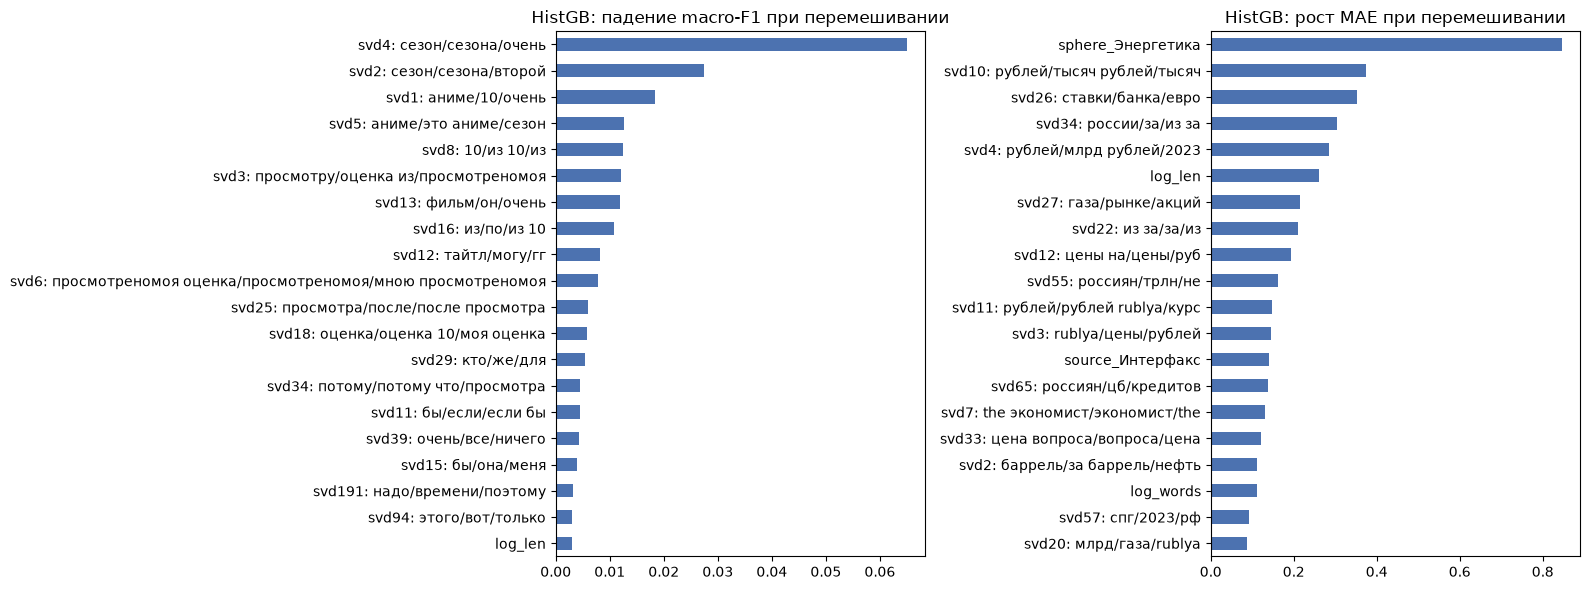

In [12]:
# У HistGradientBoosting нет встроенной важности -> permutation importance на тесте:
# насколько падает качество, если перемешать значения признака (5000 отзывов для скорости)
from sklearn.inspection import permutation_importance
names_c = FEATURE_NAMES["anime"]
names_r = FEATURE_NAMES["finnews"] + FEATURE_NAMES["meta"]
sub = np.random.default_rng(SEED).choice(len(Sa_te), 5000, replace=False)
pi_c = permutation_importance(hgb_c, Sa_te[sub], ya_te[sub], scoring="f1_macro", n_repeats=3, random_state=SEED, n_jobs=-1)
pi_r = permutation_importance(hgb_r, SMf_te, yf_te, scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=-1)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_importance(pi_c.importances_mean, names_c, "HistGB: падение macro-F1 при перемешивании", ax=ax[0])
plot_importance(pi_r.importances_mean, names_r, "HistGB: рост MAE при перемешивании", ax=ax[1])
plt.tight_layout(); plt.show()

### 3.7 Выводы по улучшению

- **H1 (плотные признаки) подтверждена:** тот же бустинг по умолчанию на LSA+статистиках даёт CV macro-F1 0.536 против 0.476 у бейзлайна на TF-IDF-1000.
- **H2 (больше итераций с ранней остановкой) подтверждена:** HistGradientBoosting с малым шагом и до 1000 итераций даёт CV macro-F1 до 0.556. Шаг 0.05 лучше 0.1 почти во всех конфигурациях.
- **H3 (сложность и регуляризация):** для классификации лучше маленькие деревья (15 листьев) с L2=1; для регрессии - крупные (63 листа). Влияние L2 небольшое (+-0.002 F1).
- **H4 (функция потерь absolute_error) подтверждена:** CV MAE 30.55 против 31.17 у лучшей конфигурации с квадратичной потерей.
- Важность признаков (permutation importance): для отзывов - LSA-компоненты про сезоны/сиквелы, "аниме/10/очень", оценки; для новостей с большим отрывом лидирует **сфера "Энергетика"**, затем компоненты "рубли/тысяч", "ставки/банк/евро", длина статьи. Бустинг, в отличие от KNN и леса, использует метаданные: сфера задаёт сдвиг масштаба влияния.
- Итог: macro-F1 **0.476 -> 0.556**, MAE **31.34 -> 29.55**.

## 4. Собственная реализация градиентного бустинга

Базовые модели - гистограммные деревья из ЛР3 (ячейка ниже). На итерации m:
`F_m = F_{m-1} + lr * h_m`, где дерево `h_m` аппроксимирует антиградиент функции потерь.

- **Регрессия (MSE):** антиградиент - остатки `g = y - F`, гессиан `h = 1`; значение листа -
  `sum(g) / (sum(h) + lambda)`, т.е. (регуляризованное) среднее остатков.
- **Классификация (softmax log-loss):** `F` - матрица логитов `(n, K)`, `g = Y_onehot - P`,
  `h = P * (1 - P)`. Вместо K отдельных деревьев строится **одно многовыходное дерево** на K градиентах (критерий -
  суммарный SSE), а значения листьев - **ньютоновский шаг** `sum(g) / (sum(h) + lambda)` отдельно по каждому классу.
- **Стохастический бустинг:** каждое дерево учится на случайной доле `subsample` объектов.
- **Ранняя остановка:** часть train откладывается под валидацию; обучение останавливается, если функция потерь на
  ней не улучшается `n_iter_no_change` итераций, и модель обрезается до лучшей итерации.

In [13]:
# Гистограммное решающее дерево CART (одинаковое в ЛР3-ЛР5)
import numpy as np


class Binner:
    """Переводит вещественные признаки в номера квантильных бинов (uint8)."""

    def __init__(self, n_bins=32):
        self.n_bins = n_bins

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        # code <= b  <=>  x <= edges[b]
        return np.stack([np.searchsorted(e, X[:, j], side="left") for j, e in enumerate(self.edges)],
                        axis=1).astype(np.uint8)


class HistTree:
    """Гистограммное дерево. G - цели/градиенты (n, K), H - гессианы (n, K) или None (=1).

    Значение листа = sum(G) / (sum(H) + reg_lambda); при H=1, lambda=0 это среднее.
    """

    def __init__(self, max_depth=8, min_samples_leaf=20, max_features=None, reg_lambda=0.0,
                 n_bins=32, random_state=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.reg_lambda = reg_lambda
        self.n_bins = n_bins
        self.rng = np.random.default_rng(random_state)

    def fit(self, X, G, H=None, binner=None, codes=None):
        G = np.asarray(G, dtype=float)
        if G.ndim == 1:
            G = G[:, None]
        H = np.ones_like(G) if H is None else np.asarray(H, dtype=float).reshape(G.shape)
        self.binner = binner or Binner(self.n_bins).fit(X)
        C = codes if codes is not None else self.binner.transform(X)
        n, F = C.shape
        self.B = max(len(e) for e in self.binner.edges) + 1
        offsets = (np.arange(F) * self.B).astype(np.int64)
        # max_features: None - все признаки, float - доля, int - количество (случайно в каждом узле)
        mf = self.max_features
        k_feat = F if mf is None else max(1, int(mf * F)) if isinstance(mf, float) else int(mf)
        max_depth = np.inf if self.max_depth is None else self.max_depth

        # Узлы хранятся в плоских списках: признак, порог, левый/правый потомок, значение листа
        self.feat, self.thr, self.left, self.right, self.value = [], [], [], [], []
        # Важность признака = суммарное уменьшение SSE (для классификации - Джини) в его разбиениях
        self.importances_ = np.zeros(F)

        def new_node(idx):
            self.feat.append(-1); self.thr.append(0.0); self.left.append(-1); self.right.append(-1)
            self.value.append(G[idx].sum(0) / (H[idx].sum(0) + self.reg_lambda))
            return len(self.feat) - 1

        stack = [(np.arange(n), new_node(np.arange(n)), 0)]
        while stack:
            idx, node, depth = stack.pop()
            m = len(idx)
            if depth >= max_depth or m < 2 * self.min_samples_leaf:
                continue
            feats = np.arange(F) if k_feat >= F else np.sort(self.rng.choice(F, k_feat, replace=False))
            flat = (C[idx][:, feats].astype(np.int64) + offsets[: len(feats)]).ravel()
            size = len(feats) * self.B
            # Гистограммы: число объектов и суммы целей в каждом (признак, бин)
            cnt = np.bincount(flat, minlength=size).reshape(len(feats), self.B)
            g = G[idx]
            sums = np.stack([np.bincount(flat, weights=np.repeat(g[:, k], len(feats)), minlength=size)
                             .reshape(len(feats), self.B) for k in range(g.shape[1])], axis=-1)
            # Накопленные суммы = статистики левой части для порога "бин <= b"
            nL = np.cumsum(cnt, axis=1)[:, :-1]
            SL = np.cumsum(sums, axis=1)[:, :-1]
            S = g.sum(0)
            nR = m - nL
            SR = S - SL
            with np.errstate(divide="ignore", invalid="ignore"):
                gain = (SL ** 2).sum(-1) / nL + (SR ** 2).sum(-1) / nR - (S ** 2).sum() / m
            gain[(nL < self.min_samples_leaf) | (nR < self.min_samples_leaf)] = -np.inf
            gain = np.nan_to_num(gain, nan=-np.inf)
            fi, b = np.unravel_index(np.argmax(gain), gain.shape)
            if not np.isfinite(gain[fi, b]) or gain[fi, b] <= 1e-12:
                continue
            f = feats[fi]
            self.importances_[f] += gain[fi, b]
            mask = C[idx, f] <= b
            self.feat[node] = int(f)
            self.thr[node] = float(self.binner.edges[f][b])
            li, ri = idx[mask], idx[~mask]
            self.left[node], self.right[node] = new_node(li), new_node(ri)
            stack.append((li, self.left[node], depth + 1))
            stack.append((ri, self.right[node], depth + 1))

        self.feat, self.thr = np.array(self.feat), np.array(self.thr)
        self.left, self.right = np.array(self.left), np.array(self.right)
        self.value = np.array(self.value)
        return self

    def predict_raw(self, X):
        """Спуск всех объектов по дереву одновременно (векторно по уровням)."""
        node = np.zeros(len(X), dtype=np.int64)
        active = self.feat[node] >= 0
        while active.any():
            a = np.where(active)[0]
            nd = node[a]
            go_left = X[a, self.feat[nd]] <= self.thr[nd]
            node[a] = np.where(go_left, self.left[nd], self.right[nd])
            active[a] = self.feat[node[a]] >= 0
        return self.value[node]

    @property
    def feature_importances_(self):
        return self.importances_ / max(self.importances_.sum(), 1e-12)

    @property
    def n_leaves(self):
        return int((self.feat < 0).sum())


class MyDecisionTreeClassifier:
    """Классификатор: дерево на one-hot целях, предсказание - класс с максимальной долей в листе."""

    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y, **fit_kw):
        self.classes_ = np.unique(y)
        Y = (y[:, None] == self.classes_[None, :]).astype(float)
        self.tree_ = HistTree(**self.kw).fit(X, Y, **fit_kw)
        return self

    def predict_proba(self, X):
        return self.tree_.predict_raw(X)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


class MyDecisionTreeRegressor:
    """Регрессор: значение листа - среднее целевой переменной."""

    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y, **fit_kw):
        self.tree_ = HistTree(**self.kw).fit(X, y, **fit_kw)
        return self

    def predict(self, X):
        return self.tree_.predict_raw(X)[:, 0]

In [14]:
class MyGradientBoosting:
    """Градиентный бустинг над гистограммными деревьями: task='clf' (softmax) или 'reg' (MSE)."""

    def __init__(self, task="reg", n_estimators=100, learning_rate=0.1, max_depth=3, min_samples_leaf=1,
                 reg_lambda=0.0, subsample=1.0, n_bins=32, early_stopping=False, validation_fraction=0.1,
                 n_iter_no_change=30, random_state=0):
        self.__dict__.update(locals()); del self.__dict__["self"]

    @staticmethod
    def _softmax(F):
        P = np.exp(F - F.max(1, keepdims=True))
        return P / P.sum(1, keepdims=True)

    def _loss(self, F, Y):
        # Функция потерь: log-loss для классификации, MSE для регрессии
        if self.task == "clf":
            return -np.mean(np.log(np.clip((self._softmax(F) * Y).sum(1), 1e-15, None)))
        return np.mean((Y[:, 0] - F[:, 0]) ** 2)

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        if self.task == "clf":
            self.classes_ = np.unique(y)
            Y = (y[:, None] == self.classes_).astype(float)
        else:
            Y = np.asarray(y, float)[:, None]
        # Отложенная валидация для ранней остановки
        if self.early_stopping:
            perm = rng.permutation(len(X)); nv = int(len(X) * self.validation_fraction)
            vi, ti = perm[:nv], perm[nv:]
            Xv, Yv, X, Y = X[vi], Y[vi], X[ti], Y[ti]
        # Начальное приближение: логарифмы априорных долей классов / среднее цели
        self.init_ = np.log(Y.mean(0)) if self.task == "clf" else Y.mean(0)
        F = np.tile(self.init_, (len(X), 1))
        binner = Binner(self.n_bins).fit(X)
        codes = binner.transform(X)
        self.trees_, self.val_loss_ = [], []
        if self.early_stopping:
            Fv = np.tile(self.init_, (len(Xv), 1)); best, best_it = np.inf, 0
        for it in range(self.n_estimators):
            # Антиградиент и гессиан функции потерь в текущей точке
            if self.task == "clf":
                P = self._softmax(F); G, H = Y - P, P * (1 - P)
            else:
                G, H = Y - F, None
            idx = rng.choice(len(X), int(self.subsample * len(X)), replace=False) if self.subsample < 1 else slice(None)
            tree = HistTree(max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf, reg_lambda=self.reg_lambda,
                            n_bins=self.n_bins).fit(None, G[idx], None if H is None else H[idx], binner=binner, codes=codes[idx])
            self.trees_.append(tree)
            F += self.learning_rate * tree.predict_raw(X)
            if self.early_stopping:
                Fv += self.learning_rate * tree.predict_raw(Xv)
                self.val_loss_.append(self._loss(Fv, Yv))
                if self.val_loss_[-1] < best - 1e-7:
                    best, best_it = self.val_loss_[-1], it
                elif it - best_it >= self.n_iter_no_change:
                    break
        if self.early_stopping:
            self.trees_ = self.trees_[:best_it + 1]                            # обрезаем до лучшей итерации
        return self

    @property
    def feature_importances_(self):
        # Суммарный выигрыш разбиений по всем деревьям ансамбля, нормированный
        imp = np.sum([t.importances_ for t in self.trees_], axis=0)
        return imp / imp.sum()

    def staged_raw(self, X):
        # Предсказания после каждой итерации (для кривых обучения)
        F = np.tile(self.init_, (len(X), 1))
        for t in self.trees_:
            F = F + self.learning_rate * t.predict_raw(X)
            yield F

    def predict(self, X):
        *_, F = self.staged_raw(X)
        return self.classes_[F.argmax(1)] if self.task == "clf" else F[:, 0]

### 4.2-4.3 Собственная реализация с параметрами бейзлайна
TF-IDF (1000 слов), 100 итераций, `learning_rate=0.1`, глубина 3, без подвыборки и регуляризации.

In [15]:
# Обучение и оценка собственного бустинга в конфигурации бейзлайна
my_c = MyGradientBoosting("clf", 100, 0.1, max_depth=3).fit(Ad_tr, ya_tr)
res["classification"]["custom"] = clf_metrics(ya_te, my_c.predict(Ad_te))
my_r = MyGradientBoosting("reg", 100, 0.1, max_depth=3).fit(Fd_tr, yf_tr)
res["regression"]["custom"] = reg_metrics(yf_te, my_r.predict(Fd_te))
results_table({t: {s: d[s] for s in ["baseline", "custom"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4755,0.5067,NaN,NaN,NaN
1,classification,custom,0.4710,0.5019,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,31.336,40.048,0.1184
3,regression,custom,NaN,NaN,31.164,39.755,0.1313


### 4.5 Выводы

Собственный бустинг (одно многовыходное дерево на softmax-градиентах с ньютоновскими листьями) в конфигурации бейзлайна сопоставим со sklearn: macro-F1 0.471 против 0.476, MAE **31.16 против 31.34** (в регрессии даже лучше). sklearn строит K=3 отдельных дерева на итерацию, наша реализация - одно общее; на 100 итерациях это даёт почти то же качество при втрое меньшем числе деревьев.

### 4.6-4.8 Собственная реализация + техники улучшенного бейзлайна
Плотные признаки, малый шаг и много итераций с ранней остановкой, L2-регуляризация листьев, стохастическая
подвыборка 80%. Глубина подбирается так, чтобы число листьев соответствовало лучшему `max_leaf_nodes`
(у HistGradientBoosting деревья растут по листьям, у нашей реализации - по уровням).

In [16]:
# Собственный бустинг с техниками улучшенного бейзлайна
depth = lambda leaves: int(np.ceil(np.log2(leaves)))
common_my = dict(n_estimators=1500, min_samples_leaf=20, subsample=0.8, early_stopping=True, random_state=SEED)
my_c2 = MyGradientBoosting("clf", learning_rate=pc["learning_rate"], max_depth=depth(pc["max_leaf_nodes"]),
                           reg_lambda=max(pc["l2_regularization"], 1.0), **common_my).fit(Sa_tr, ya_tr)
res["classification"]["custom_improved"] = clf_metrics(ya_te, my_c2.predict(Sa_te))
my_r2 = MyGradientBoosting("reg", learning_rate=pr["learning_rate"], max_depth=depth(pr["max_leaf_nodes"]),
                           reg_lambda=max(pr["l2_regularization"], 1.0), **common_my).fit(SMf_tr, yf_tr)
res["regression"]["custom_improved"] = reg_metrics(yf_te, my_r2.predict(SMf_te))
print("итераций:", len(my_c2.trees_), len(my_r2.trees_))
results_table({t: {s: d[s] for s in ["improved", "custom_improved"]} for t, d in res.items()})

итераций: 457 232


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,improved,0.5559,0.5667,NaN,NaN,NaN
1,classification,custom_improved,0.5483,0.5586,NaN,NaN,NaN
2,regression,improved,NaN,NaN,29.545,38.639,0.1794
3,regression,custom_improved,NaN,NaN,30.060,38.614,0.1805


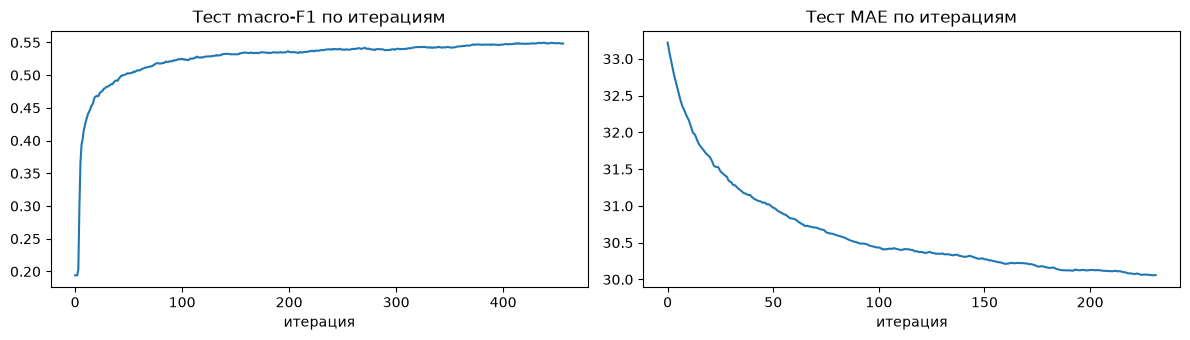

In [17]:
# Кривые обучения собственного бустинга: качество на тесте в зависимости от числа итераций
f1s = [clf_metrics(ya_te, my_c2.classes_[F.argmax(1)])["f1_macro"] for F in my_c2.staged_raw(Sa_te)]
maes = [reg_metrics(yf_te, F[:, 0])["mae"] for F in my_r2.staged_raw(SMf_te)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(f1s); ax[0].set(title="Тест macro-F1 по итерациям", xlabel="итерация")
ax[1].plot(maes); ax[1].set(title="Тест MAE по итерациям", xlabel="итерация"); plt.tight_layout(); plt.show()

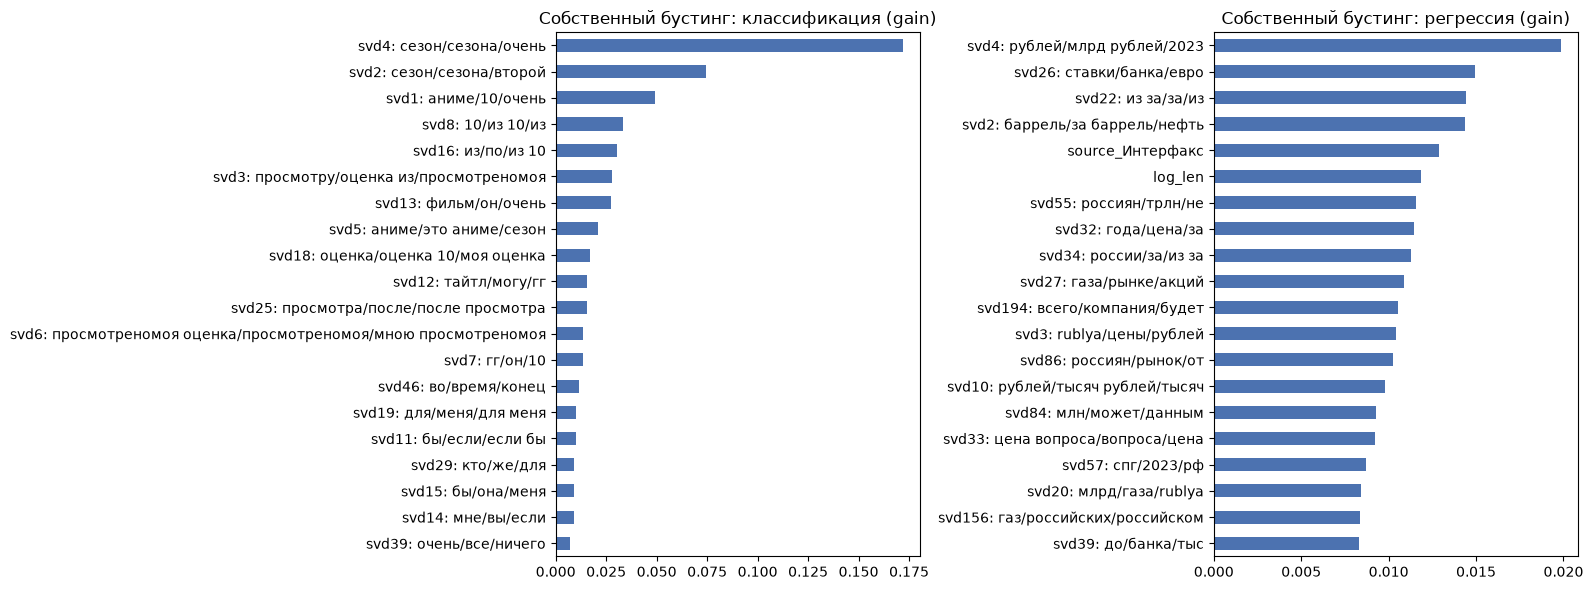

In [18]:
# Важность признаков собственного бустинга (gain) - сравнение с permutation importance выше
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_importance(my_c2.feature_importances_, names_c, "Собственный бустинг: классификация (gain)", ax=ax[0])
plot_importance(my_r2.feature_importances_, names_r, "Собственный бустинг: регрессия (gain)", ax=ax[1])
plt.tight_layout(); plt.show()

Примечание: собственная реализация регрессии обучается только с квадратичной функцией потерь, поэтому при выборе
`absolute_error` в улучшенном бейзлайне это различие сохраняется.

### 4.10 Выводы

С техниками улучшенного бейзлайна (LSA-признаки, шаг 0.05, ранняя остановка, L2-регуляризация листьев, подвыборка 80%) собственный бустинг даёт macro-F1 **0.548** (sklearn 0.556) и MAE **30.06** (sklearn 29.55). Отставание в регрессии объясняется функцией потерь: sklearn выбрал `absolute_error`, а собственная реализация обучается только с квадратичной; по RMSE и R2 собственный бустинг даже лучше (38.61 / 0.181 против 38.64 / 0.179). Кривые обучения монотонны: ранняя остановка сработала на ~460 итерациях для классификации и ~230 для регрессии.

## Сравнение всех этапов

Сводная таблица метрик на тестовой выборке: бейзлайн (п.2), улучшенный бейзлайн (п.3), собственная реализация (п.4) и собственная реализация с техниками улучшенного бейзлайна.

In [19]:
# Таблица метрик по всем этапам и сохранение в labs/results/LR5.json для итогового ноутбука
table = results_table(res)
save_results("LR5", res)
table

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4755,0.5067,NaN,NaN,NaN
1,classification,improved,0.5559,0.5667,NaN,NaN,NaN
2,classification,custom,0.4710,0.5019,NaN,NaN,NaN
3,classification,custom_improved,0.5483,0.5586,NaN,NaN,NaN
4,regression,baseline,NaN,NaN,31.336,40.048,0.1184
5,regression,improved,NaN,NaN,29.545,38.639,0.1794
6,regression,custom,NaN,NaN,31.164,39.755,0.1313
7,regression,custom_improved,NaN,NaN,30.060,38.614,0.1805


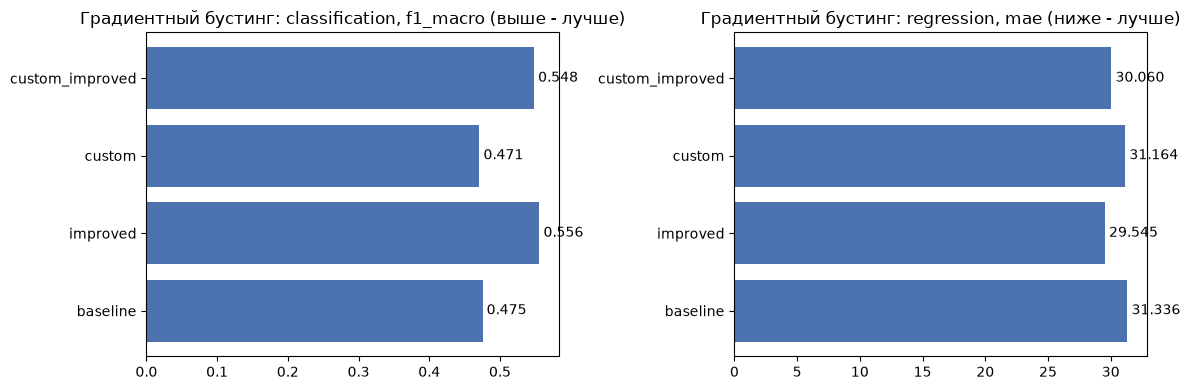

In [20]:
# Визуальное сравнение основной метрики каждой задачи по этапам
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (task, metric) in zip(ax, [("classification", "f1_macro"), ("regression", "mae")]):
    t = table[table["задача"] == task]
    a.barh(t["этап"], t[metric], color="#4C72B0")
    a.set_title(f"Градиентный бустинг: {task}, {metric}" + (" (выше - лучше)" if metric == "f1_macro" else " (ниже - лучше)"))
    for i, v in enumerate(t[metric]):
        a.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## Выводы

1. Градиентный бустинг - **лучший нелинейный алгоритм** в обеих задачах (macro-F1 0.556, MAE 29.55, R2 0.18) и единственный, который приблизился к линейным моделям.
2. Главные источники прироста: плотные признаки, малый шаг с ранней остановкой и функция потерь, совпадающая с целевой метрикой (MAE).
3. Собственная реализация уступает sklearn не более 0.01 F1 и 0.5 MAE; разница объясняется функцией потерь и устройством деревьев (по уровням, а не по листьям).
4. Итоговое сравнение всех алгоритмов - в `LR_summary.ipynb`.